In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

def f(x):
    return 3*x**2 - 4*x + 5

# print(f(3.0))

# xs = np.arange(-5, 5, 0.25)
# ys = f(xs)
# plt.plot(xs,ys)


In [13]:
from microg.engine import Value

a = Value(2.0, label='a')
b = Value(-3.0, label='a')
c = Value(10.0, label='a')
d = a*b+c





In [11]:
from graphviz import Digraph

def trace(root) -> tuple [set,set]:
    #
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir':'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        #
        dot.node(
                 name  = uid,
                 label = "{data % .4f}" % (n.data, ),
                 shape = 'record'
                )
        if n._op:
            #
            dot.node(name = uid + n._op, label = n._op)

            dot.edge(uid + n._op, uid)

    for n1,n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


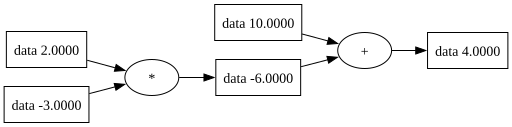

In [14]:
draw_dot(d)